In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,accuracy_score,precision_score,recall_score,f1_score, classification_report)
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv('/content/Titanic-Dataset.csv')

In [ ]:
df = df.drop(['PassengerId','Name','Ticket','Cabin'],axis=1)
df['Age'] = df['Age'].fillna(df['Age'].median())
df['Embarked'] = df['Embarked'].fillna(df['Embarked'].mode()[0])
df['Sex'] = df['Sex'].map({'male':0,'female':1})
df['Embarked'] = df['Embarked'].map({'S':0,'C':1,'Q':2})



In [ ]:
x = df[['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked']]
y = df['Survived']

In [ ]:
X_tr,X_te,y_tr,y_te=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [ ]:
  clf = LogisticRegression(max_iter=1000)
clf.fit(X_tr, y_tr)
y_pred = clf.predict(X_te)

In [ ]:
print('Accuracy:', round(accuracy_score(y_te, y_pred), 3))
print('Precision:', round(precision_score(y_te, y_pred), 3))
print('Recall:', round(recall_score(y_te, y_pred), 3))
print('F1 Score:', round(f1_score(y_te, y_pred), 3))
print('\n', classification_report(y_te, y_pred))

Accuracy: 0.804
Precision: 0.793
Recall: 0.667
F1 Score: 0.724

               precision    recall  f1-score   support

           0       0.81      0.89      0.85       110
           1       0.79      0.67      0.72        69

    accuracy                           0.80       179
   macro avg       0.80      0.78      0.79       179
weighted avg       0.80      0.80      0.80       179



confusion Matrix:
 [[98 12]
 [23 46]]


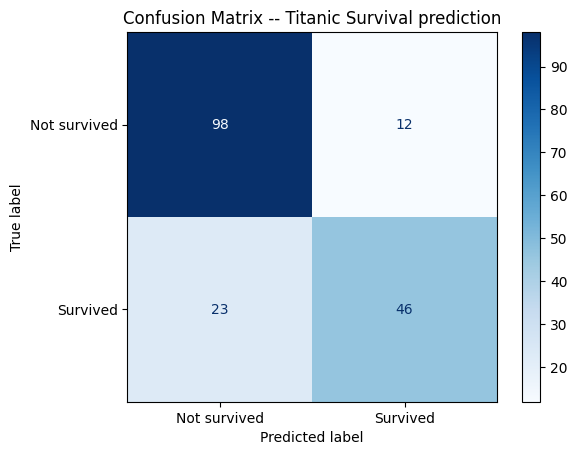

In [ ]:
cm = confusion_matrix(y_te, y_pred, labels=[0, 1])
print('confusion Matrix:\n', cm)
ConfusionMatrixDisplay(cm, display_labels=['Not survived', 'Survived']).plot(cmap='Blues')
plt.title('Confusion Matrix -- Titanic Survival prediction')
plt.show()
